In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['font.family'] = 'Liberation Sans'
rcParams['font.size'] = 12
rcParams['figure.autolayout'] = True
rcParams["savefig.bbox"] = 'tight'
rcParams["savefig.format"] = 'png'
rcParams["savefig.dpi"] = 150
rcParams["grid.linestyle"] = '--'

# from matplotlib_inline import backend_inline
# backend_inline.set_matplotlib_formats('svg')

In [2]:
import os
import torch
import h5py
from glob import glob
import pandas as pd

import NbDasUtils as utils
from NbDas import DasData 

In [3]:
%matplotlib inline

In [4]:
if not os.path.exists("./figures"):
    os.makedirs("./figures")

## Read DAS Strain rate H5 file

In [5]:
h5_filepath = "./strainrate/Route9_SR5m_GL5m_SV5m_StrainRate_20220906T103239+0900_93.h5"

h5_file = h5py.File(h5_filepath, "r")

print("Reading DAS data from HDF5 file: ", h5_filepath)
(
    das_data,
    spatial_sampling_interval,
    time_sampling_interval,
    time_series,
    dist_series,
) = utils.read_h5(h5_file)

# apply highpass filter to remove low frequency noise
print("Applying highpass filter...")
das_data = utils.sos_highpass_filter(das_data, 3, cutf=0.5, fs=1/time_sampling_interval)

# cut time from 20s to 40s
# das_data, time_series = utils.crop_das_time_range(das_data, time_series, (25, 25+12+time_sampling_interval))
# das_data, dist_series = utils.crop_das_distance_range(das_data, dist_series, (0, 30000))

time_sampling_interval = (time_series[1] - time_series[0]).round(6)
spatial_sampling_interval = (dist_series[1] - dist_series[0]).round(6)
sps = (1/time_sampling_interval).round(6)

RESAMPLE = True
candidate_sps = 100  # required sampling rate in Sps (Actual, updated sps may be different after resampling)

if sps > candidate_sps and RESAMPLE:
    decimation_factor = int(sps/candidate_sps)

    from scipy.signal import decimate
    print(f"Decimation factor: {decimation_factor}")
    
    # simple downsample by decimation (caution: may cause aliasing)
    # das_data = das_data[::decimation_factor, :]

    das_data = decimate(das_data, decimation_factor, axis=0, zero_phase=True)
    # update distance and time series
    sps = sps / decimation_factor
    time_sampling_interval = 1 / sps
    
    print(f"New sps: {sps}")
    print("New shape of DAS data after resampling: ", das_data.shape)

# set beginning time to zero
time_series = np.arange(0, das_data.shape[0]*time_sampling_interval, time_sampling_interval)

das_data = DasData(das_data, spatial_sampling_interval, time_sampling_interval, dist_series, time_series)

print("DAS data shape after filtering: ", das_data.data.shape)

Reading DAS data from HDF5 file:  ./strainrate/Route9_SR5m_GL5m_SV5m_StrainRate_20220906T103239+0900_93.h5
DAS data shape: (30000, 10149)
Applying highpass filter...
Decimation factor: 5
New sps: 100.0
New shape of DAS data after resampling:  (6000, 10149)
DAS data shape after filtering:  (6000, 10149)


In [6]:
# save the preprocessed DAS data to a new HDF5 file
if RESAMPLE:
    new_file_name = f"Route9_SR5m_GL5m_SV_StrainRate_Downsampled{int(sps)}Sps.h5"
else:
    new_file_name = "Route9_SR5m_GL5m_SV_StrainRate_Cropped.h5"
    
output_h5_filepath = "./strainrate/" + new_file_name
print("Saving preprocessed DAS data to HDF5 file: ", output_h5_filepath)

new_h5_file = h5py.File(output_h5_filepath, "w")

dset_write = new_h5_file.create_dataset("Acoustic", data=das_data.data, dtype=np.float32)

# copy attributes
for attr in h5_file["Acoustic"].attrs:
    dset_write.attrs[attr] = h5_file["Acoustic"].attrs[attr]
# set new attributes
dset_write.attrs["TimeSamplingInterval(seconds)"] = time_sampling_interval.astype(np.float32)
dset_write.attrs["SpatialSamplingInterval"] = spatial_sampling_interval.astype(np.float32)
dset_write.attrs["InterrogationRate(Hz)"] = sps.astype(np.float32)
dset_write.attrs["StartPosition"] = dist_series[0].astype(np.float32)
dset_write.attrs["StopPosition"] = dist_series[-1].astype(np.float32)

new_h5_file.close()
# h5_file.close()

Saving preprocessed DAS data to HDF5 file:  ./strainrate/Route9_SR5m_GL5m_SV_StrainRate_Downsampled100Sps.h5


Time downsample factor:  1
Distance downsample factor:  3


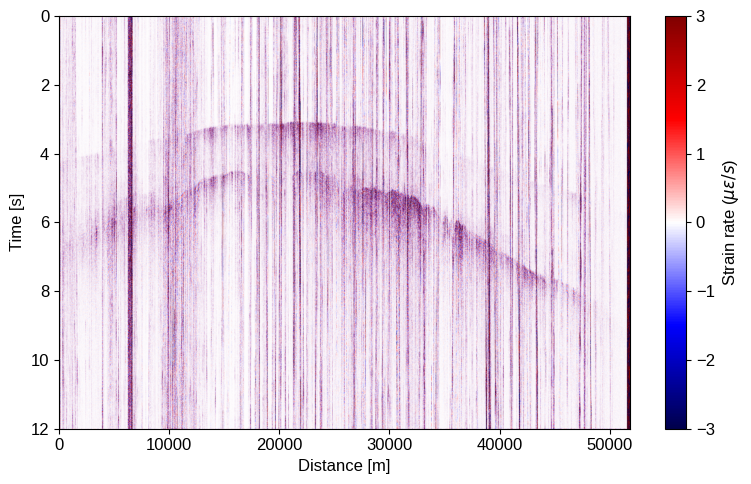

In [15]:
plt.figure(figsize=(8, 5))
das_data.plot_data(cmap="seismic", vmin=-3, vmax=3)
plt.grid(False)
plt.savefig(f"./figures/{new_file_name.replace('.h5', '.png')}")
plt.show()

Time downsample factor:  1
Distance downsample factor:  3


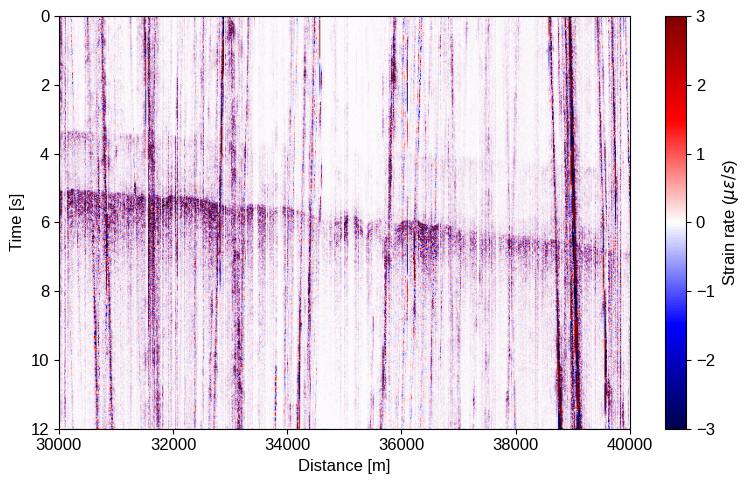

In [16]:
plt.figure(figsize=(8, 5))
das_data.plot_data(cmap="seismic", vmin=-3, vmax=3)

plt.grid(False)
plt.xlim(30000, 40000)
plt.savefig(f"./figures/{new_file_name.replace('.h5', '')}_30-40km.png")
plt.show()

## Run PhaseNet-DAS

In [17]:
# Write input file to files.txt
with open("files.txt", "w") as f:
    f.write(f"strainrate/{new_file_name}\n")

In [18]:
# ngpu = torch.cuda.device_count()
ngpu = 0 # force CPU mode
base_cmd = "../predict.py --model phasenet_das --data_list=files.txt  --data_path ./strainrate --result_path ./results --format=h5  --batch_size 1 --workers 0"

In [19]:
if ngpu == 0:
    cmd = f"python {base_cmd} --device cpu --system neubrex"
elif ngpu == 1:
    cmd = f"python {base_cmd} --system neubrex"
else:
    cmd = f"torchrun --nproc_per_node {ngpu} {base_cmd} --system neubrex"

# print(cmd)
# os.system(cmd)

## Benchmarking PhaseNet-DAS

In [20]:
# import parent path
import sys
import os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))

import eqnet.models.phasenet_das
from eqnet.data import DASIterableDataset
from eqnet.utils import detect_peaks, extract_picks
from contextlib import nullcontext
from tqdm import tqdm
import time

# Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
phases = ["P", "S"]
min_prob = 0.3
batch_size = 8  # Batch size for processing patches

print(f"Device: {device}")
print(f"Phases: {phases}")
print(f"Minimum probability: {min_prob}")
print(f"Batch size: {batch_size}")

Device: cuda
Phases: ['P', 'S']
Minimum probability: 0.3
Batch size: 8


In [21]:
# Build PhaseNet-DAS model
print("Building PhaseNet-DAS model...")
model = eqnet.models.phasenet_das.build_model(
    backbone="unet",
    in_channels=1,
    out_channels=len(phases) + 1  # P, S, + noise
)

# Load checkpoint from torch hub
model_url = "https://github.com/AI4EPS/models/releases/download/PhaseNet-DAS-v1/PhaseNet-DAS-v1.pth"
print(f"Loading checkpoint from: {model_url}")
checkpoint = torch.hub.load_state_dict_from_url(
    model_url, 
    model_dir="./model_phasenet_das", 
    progress=True, 
    map_location="cpu"
)

# Load state dict and move to device
model.load_state_dict(checkpoint["model"], strict=True)
model.to(device)
model.eval()
print("Model loaded successfully!")

# Warmup: run a dummy forward pass
print("Warming up GPU...")
dummy_input = {"data": torch.randn(1, 1, 1024*20, 1024*5).to(device)}
with torch.inference_mode():
    ctx = nullcontext() if device.type == "cpu" else torch.amp.autocast(device_type=device.type, dtype=torch.float16)
    with ctx:
        _ = model(dummy_input)
print("Warmup complete!")

Building PhaseNet-DAS model...
Loading checkpoint from: https://github.com/AI4EPS/models/releases/download/PhaseNet-DAS-v1/PhaseNet-DAS-v1.pth
Model loaded successfully!
Warming up GPU...
Warmup complete!


In [22]:
# Create dataset to iterate through and preload all patches
print("Creating dataset and loading all patches into RAM...")

dataset = DASIterableDataset(
    data_path="../data/strainrate",
    data_list="files.txt",
    format="h5",
    nx=1024*5,  # spatial samples per patch
    nt=1024*20, # time samples per patch
    training=False,
    system="neubrex",
    cut_patch=False,  # default overlap strategy
    rank=0,
    world_size=1
)

# Preload all data into memory organized by file
preloaded_data = {}
current_file = None
file_patches = []

print("Loading patches...")
for i, meta in enumerate(tqdm(dataset, desc="Loading patches")):
    file_name = meta["file_name"][0] if isinstance(meta["file_name"], list) else meta["file_name"]
    
    # When we encounter a new file, save previous file's patches
    if current_file is not None and file_name != current_file:
        preloaded_data[current_file] = file_patches
        file_patches = []
    
    current_file = file_name
    
    # Store patch with all necessary metadata
    file_patches.append({
        "data": meta["data"].clone(),  # Clone to ensure independence
        "nt": meta["nt"],
        "nx": meta["nx"],
        "dt_s": meta["dt_s"],
        "dx_m": meta["dx_m"],
        "file_name": file_name,
        "begin_time_index": meta.get("begin_time_index"),
        "begin_channel_index": meta.get("begin_channel_index"),
    })

# Don't forget the last file
if current_file is not None:
    preloaded_data[current_file] = file_patches

print(f"\nLoaded {len(preloaded_data)} files into RAM:")
for file_name, patches in preloaded_data.items():
    print(f"  {file_name}: {len(patches)} patches")

Creating dataset and loading all patches into RAM...
Total samples: 1 files
Loading patches...


Loading patches: 100%|██████████| 1/1 [00:00<00:00,  3.15it/s]


Loaded 1 files into RAM:
  strainrate/Route9_SR5m_GL5m_SV_StrainRate_Cropped_Downsampled100Sps.h5: 1 patches


In [23]:
# print shape of the patch
print("Shape of first patch data: ", end="")
print(preloaded_data[list(preloaded_data.keys())[0]][0]["data"].shape)

Shape of first patch data: torch.Size([1, 2048, 10240])


Run inference with timing

In [24]:
# Postprocessing function (from predict.py)
def postprocess(meta, output):
    nt, nx = meta["nt"], meta["nx"]
    data = meta["data"][:, :, :nt, :nx]
    meta["data"] = data
    if "phase" in output:
        output["phase"] = output["phase"][:, :, :nt, :nx]
    return meta, output

# Setup result directory
pick_path = "./results/picks_phasenet_das"
os.makedirs(pick_path, exist_ok=True)

# Process each file and benchmark
all_timings = {}
all_picks = {}

print("\n" + "="*80)
print("BENCHMARK: Inference + Post-processing")
print("="*80)

for file_name, patches in preloaded_data.items():
    print(f"\nProcessing: {file_name}")
    print(f"  Number of patches: {len(patches)}")
    
    file_start = time.time()
    
    # Process patches in batches
    all_file_picks = []
    
    for batch_start in range(0, len(patches), batch_size):
        batch_end = min(batch_start + batch_size, len(patches))
        batch_patches = patches[batch_start:batch_end]
        actual_batch_size = len(batch_patches)
        
        # Stack batch data
        batch_data = torch.stack([p["data"] for p in batch_patches]).to(device)
        batch_nt = batch_patches[0]["nt"]
        batch_nx = batch_patches[0]["nx"]
        
        # Prepare meta dict - always convert to float for extract_picks compatibility
        # extract_picks checks isinstance(dt, float), so convert numpy scalars to Python float
        dt_s = float(batch_patches[0]["dt_s"])
        dx_m = float(batch_patches[0]["dx_m"])
        
        meta = {
            "data": batch_data,
            "nt": batch_nt,
            "nx": batch_nx,
            "file_name": [p["file_name"] for p in batch_patches],
            "begin_time_index": torch.tensor([p["begin_time_index"] for p in batch_patches]) if batch_patches[0]["begin_time_index"] is not None else None,
            "begin_channel_index": torch.tensor([p["begin_channel_index"] for p in batch_patches]) if batch_patches[0]["begin_channel_index"] is not None else None,
            "dt_s": dt_s,
            "dx_m": dx_m,
        }
        
        # Run inference
        with torch.inference_mode():
            ctx = nullcontext() if device.type == "cpu" else torch.amp.autocast(device_type=device.type, dtype=torch.float16)
            with ctx:
                output = model(meta)
        
        # Post-process
        meta, output = postprocess(meta, output)
        scores = torch.softmax(output["phase"], dim=1)
        
        # Detect peaks
        topk_scores, topk_inds = detect_peaks(scores, vmin=min_prob, kernel=21)
        
        # Extract picks
        picks_ = extract_picks(
            topk_inds,
            topk_scores,
            file_name=meta["file_name"],
            begin_time=None,
            begin_time_index=meta["begin_time_index"] if meta["begin_time_index"] is not None else None,
            begin_channel_index=meta["begin_channel_index"] if meta["begin_channel_index"] is not None else None,
            dt=meta["dt_s"],
            vmin=min_prob,
            phases=phases,
        )
        
        # Accumulate picks
        for i in range(actual_batch_size):
            if len(picks_[i]) > 0:
                all_file_picks.extend(picks_[i])
    
    file_end = time.time()
    elapsed = file_end - file_start
    
    # Store timing
    all_timings[file_name] = elapsed
    all_picks[file_name] = all_file_picks
    
    print(f"  Processing time: {elapsed:.4f} seconds")
    print(f"  Number of picks: {len(all_file_picks)}")
    print(f"  Throughput: {len(patches)/elapsed:.2f} patches/sec")

print("\n" + "="*80)
print("BENCHMARK SUMMARY")
print("="*80)
total_time = sum(all_timings.values())
total_patches = sum(len(patches) for patches in preloaded_data.values())
print(f"Total processing time: {total_time:.4f} seconds")
print(f"Total patches: {total_patches}")
print(f"Average throughput: {total_patches/total_time:.2f} patches/sec")
print("="*80)


BENCHMARK: Inference + Post-processing

Processing: strainrate/Route9_SR5m_GL5m_SV_StrainRate_Cropped_Downsampled100Sps.h5
  Number of patches: 1
  Processing time: 10.6061 seconds
  Number of picks: 20362
  Throughput: 0.09 patches/sec

BENCHMARK SUMMARY
Total processing time: 10.6061 seconds
Total patches: 1
Average throughput: 0.09 patches/sec


In [25]:
# Save picks to CSV files for compatibility with plotting code
print("\nSaving picks to CSV files...")
for file_name, picks in all_picks.items():
    # Extract filename for CSV
    filename = file_name.split("/")[-1].replace(".h5", "")
    csv_path = os.path.join(pick_path, filename + ".csv")
    
    if len(picks) == 0:
        # Create empty file
        with open(csv_path, "w") as f:
            pass
        print(f"  Saved (empty): {csv_path}")
    else:
        # Convert to DataFrame and save
        picks_df = pd.DataFrame(picks)
        picks_df["channel_index"] = picks_df["station_id"].apply(lambda x: int(x))
        picks_df.sort_values(by=["channel_index", "phase_index"], inplace=True)
        picks_df.to_csv(
            csv_path,
            columns=["channel_index", "phase_index", "phase_time", "phase_score", "phase_type"],
            index=False,
        )
        print(f"  Saved: {csv_path} ({len(picks)} picks)")

print("Done!")


Saving picks to CSV files...
  Saved: ./results/picks_phasenet_das/Route9_SR5m_GL5m_SV_StrainRate_Cropped_Downsampled100Sps.csv (20362 picks)
Done!


## Plot results

In [26]:
picks = pd.read_csv(f"results/picks_phasenet_das/" + new_file_name.replace(".h5", ".csv"))
picks.head()

,channel_index,phase_index,phase_time,phase_score,phase_type
0,0,412,1970-01-01T00:00:04.120,0.763,P
1,0,678,1970-01-01T00:00:06.780,0.699,S
2,1,412,1970-01-01T00:00:04.120,0.820,P
3,1,677,1970-01-01T00:00:06.770,0.778,S
4,2,413,1970-01-01T00:00:04.130,0.865,P


Time downsample factor:  1
Distance downsample factor:  3


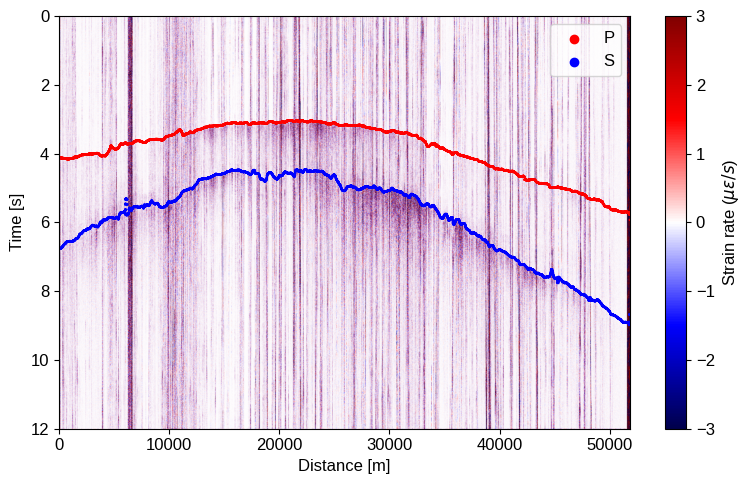

In [27]:
plt.figure(figsize=(8, 5))
das_data.plot_data(cmap="seismic", title="", vmin=-3, vmax=3)
color = picks["phase_type"].map({"P": "r", "S": "b"})
dx = spatial_sampling_interval
dt = time_sampling_interval
plt.scatter(picks["channel_index"].values * dx, picks["phase_index"].values * dt + time_series[0], c=color, s=0.5)
plt.scatter([], [], c="r", label="P")
plt.scatter([], [], c="b", label="S")
plt.legend()
plt.xlabel("Distance [m]")
plt.ylabel("Time [s]")
plt.savefig(f"./figures/{new_file_name.replace('.h5', '')}_picks.png")

Time downsample factor:  1
Distance downsample factor:  3


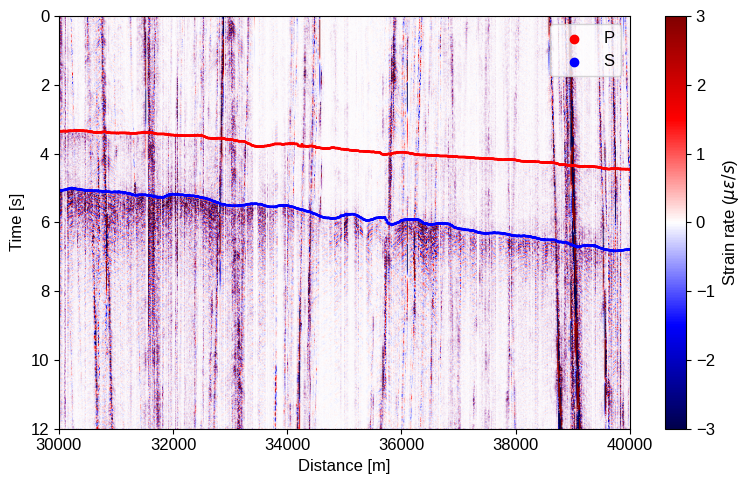

In [28]:
plt.figure(figsize=(8, 5))
das_data.plot_data(cmap="seismic", title="", vmin=-3, vmax=3)
color = picks["phase_type"].map({"P": "r", "S": "b"})
dx = spatial_sampling_interval
dt = time_sampling_interval
plt.scatter(picks["channel_index"].values * dx, picks["phase_index"].values * dt + time_series[0], c=color, s=0.5)
plt.scatter([], [], c="r", label="P")
plt.scatter([], [], c="b", label="S")
plt.legend()
plt.xlabel("Distance [m]")
plt.ylabel("Time [s]")
plt.xlim(30000, 40000)
plt.savefig(f"./figures/{new_file_name.replace('.h5', '')}_picks_30km-40km.png")